## Run in Colab or Jupyter
Use a fresh **Python 3.12 CPU runtime** (Runtime → Change runtime type; select **2026.07** if needed), then **Run all**. If setup requests it, restart the session once and run all again. Setup downloads checksum-verified helper release **0.1.0** and installs pinned dependencies. NB-01 reuses the published triangle fixture. No new synthetic observations are generated.

When prompted, upload the separately supplied **`nb-11-capacity-inputs-v1.zip`**. Observed input files are not published with the helpers. Upload sends them to your Google runtime; it does not add them to GitHub. The notebook makes no live data requests. For local Jupyter, set `BOOK_LABS_INPUT_ZIP` to that archive before running. Do not share notebooks with unreviewed sensitive outputs.

The outputs below are the previously reviewed reader results. Rerunning replaces them with your execution results.

In [ ]:
# Versioned helper setup: run before the teaching cells.
import hashlib, importlib.metadata, io, os, pathlib, subprocess, sys, tempfile, urllib.request, zipfile
if sys.version_info[:2] != (3, 12):
    raise RuntimeError("Select a Python 3.12 runtime before running this release.")
release_url = 'https://github.com/sherandoresearch/power-markets-notebooks/releases/download/book-labs-v0.1.0/book-labs-v0.1.0.zip'
expected_sha256 = 'c133ed6a5782865b564c1619bfcc2c9e42274eda343480102236a9fafaabb76d'
local_archive = os.environ.get("BOOK_LABS_RELEASE_ZIP")
archive_bytes = pathlib.Path(local_archive).read_bytes() if local_archive else urllib.request.urlopen(release_url, timeout=90).read()
if hashlib.sha256(archive_bytes).hexdigest() != expected_sha256:
    raise ValueError("Helper release checksum mismatch")
root = pathlib.Path(tempfile.mkdtemp(prefix="power-book-labs-0.1.0-"))
with zipfile.ZipFile(io.BytesIO(archive_bytes)) as archive:
    for info in archive.infolist():
        member = pathlib.PurePosixPath(info.filename)
        if member.is_absolute() or ".." in member.parts or (info.external_attr >> 16) & 0o170000 == 0o120000:
            raise ValueError("Unsafe helper archive member")
    if sum(i.file_size for i in archive.infolist()) > 10_000_000:
        raise ValueError("Helper archive too large")
    archive.extractall(root)
requirements = (root / "requirements.txt").read_text().splitlines()
modules = {"PyYAML": "yaml"}
restart_required = []
for requirement in requirements:
    package, version = requirement.split("==")
    module = modules.get(package, package)
    if module in sys.modules and importlib.metadata.version(package) != version:
        restart_required.append(package)
subprocess.check_call([sys.executable, "-m", "pip", "install", "--quiet", "-r", str(root / "requirements.txt")])
if restart_required:
    raise RuntimeError("Dependencies installed. Restart session, then Run all again: " + ", ".join(restart_required))
for requirement in requirements:
    package, version = requirement.split("==")
    if importlib.metadata.version(package) != version:
        raise RuntimeError("Dependency version mismatch: " + package)
# Remove a previous run's helper modules when rerunning setup in the same kernel.
for module in list(sys.modules):
    if module == "book_labs" or module.startswith("book_labs."):
        del sys.modules[module]
sys.path.insert(0, str(root / "src"))
os.environ["BOOK_LABS_ROOT"] = str(root)
print("Helper release 0.1.0 verified and ready.")


In [ ]:
# Private inputs: select the separately provided ZIP; nothing is fetched from EWB.
from book_labs.upload import import_bundle
input_path = os.environ.get("BOOK_LABS_INPUT_ZIP")
if input_path:
    import_bundle(pathlib.Path(input_path).read_bytes())
else:
    try:
        from google.colab import files
    except ImportError as exc:
        raise RuntimeError("Set BOOK_LABS_INPUT_ZIP to the private ZIP before running in local Jupyter.") from exc
    uploaded = files.upload()
    if len(uploaded) != 1:
        raise ValueError("Upload exactly one file: nb-11-capacity-inputs-v1.zip")
    import_bundle(next(iter(uploaded.values())))
    del uploaded


# NB-11-CAPACITY — Physical use and booked capacity
**Question:** when is flow divided by capacity meaningful? This companion to
NB-11-ENTSOG uses the same real DIS-00191 / BE-TSO-0001 hourly flow panel,
adding retained technical, available, booked and interruptible intervals.
The window is three gas days, 10–12 October 2026 (04:00 UTC to 04:00 UTC).
No synthetic observations are created. Prerequisites: interval joins, units,
and the distinction between physical throughput and contractual rights.
We audit the denominator, calculate a bounded utilization ratio, and preserve
zero-denominator cases. Reruns need repository-local helpers and private inputs.

In [1]:
import os,sys,json
from pathlib import Path
import numpy as np
root=Path(os.environ['BOOK_LABS_ROOT']);sys.path.insert(0,str(root/'src'))
from book_labs import capacity_availability as observed
from book_labs.runtime import setup_plot,record
c=observed.capacity();entry=c['directions']['entry'];exit=c['directions']['exit']
print(json.dumps(c['audit'],indent=2))
for direction,d in c['directions'].items():print(direction,{'hours':len(d['flow']),'flow_status':d['status'],'overlap_hours':d['overlap_hours']})

{
  "capacity-technical": {
    "rows": 13,
    "collector_asof_equal": true
  },
  "capacity-available": {
    "rows": 2,
    "collector_asof_equal": true
  },
  "firm-booked": {
    "rows": 12,
    "collector_asof_equal": true
  },
  "interruptible": {
    "rows": 6,
    "collector_asof_equal": true
  }
}
entry {'hours': 72, 'flow_status': {'Confirmed': 72}, 'overlap_hours': 0}
exit {'hours': 72, 'flow_status': {'Provisional': 72}, 'overlap_hours': 0}


## 1. Interval containment, not equality on a date
The four capacity captures contain 33 intervals, including historical periods.
Match point, operator and direction, retaining indicator identity. A capacity
interval must contain the entire flow hour: `valid_from ≤ hour_start` and
`hour_end ≤ valid_to`. The snapshot matches the retained flows:
`entsog-20261015T122505Z-cfb5bf43`. Units are kWh/h throughout; an hourly
integral is kWh of gas energy. Dividing by 1,000 gives MWh of gas,
not electrical output; conversion to electricity requires a plant model.

The API filters capacity by interval **start**, not overlap. A retained query
with the flow window's lower start returns zero technical-capacity rows. That
does not mean capacity is zero or unknown: the relevant interval began earlier.
Query the selected entity without a lower start bound, then perform containment.
For overlapping intervals the descriptor recommends the newest start; ambiguous
equal-start candidates must fail. No overlaps occur in this sample.

In [2]:
print('Technical rows when incorrectly applying the flow lower bound:',c['narrow_query_rows'])
assert c['narrow_query_rows']==0
for direction,d in c['directions'].items():
    print(direction,{k:np.unique(v).tolist() for k,v in d['values'].items()})
    assert d['overlap_hours']==0

Technical rows when incorrectly applying the flow lower bound: 0
entry {'Firm Available': [0.0], 'Firm Booked': [0.0], 'Firm Technical': [0.0], 'Interruptible Available': [0.0], 'Interruptible Booked': [0.0], 'Interruptible Total': [0.0]}
exit {'Firm Available': [0.0], 'Firm Booked': [44925471.0], 'Firm Technical': [44925471.0], 'Interruptible Available': [0.0], 'Interruptible Booked': [0.0], 'Interruptible Total': [0.0]}


## 2. A positive exit denominator and an undefined entry ratio
Exit technical capacity is 44,925,471 kWh/h. The 72 observed flow rates range
from 4,088,560 to 12,281,260 kWh/h. Utilization is the reported flow divided by
technical capacity for the same direction and full hour. It is descriptive,
not a measure of available capacity for a proposed transaction.
Entry has 72 zero flows and 72 zero capacities. Its 0/0 ratio is undefined;
neither zero filling nor an epsilon denominator is justified.
All exit flow rows are **Provisional**; all entry rows are Confirmed. The exit
percentages describe this retained vintage and may change with revisions.

Exit utilization min / mean / max (%): [9.101, 14.389, 27.337]
Entry undefined hours: 72


Matplotlib is building the font cache; this may take a moment.


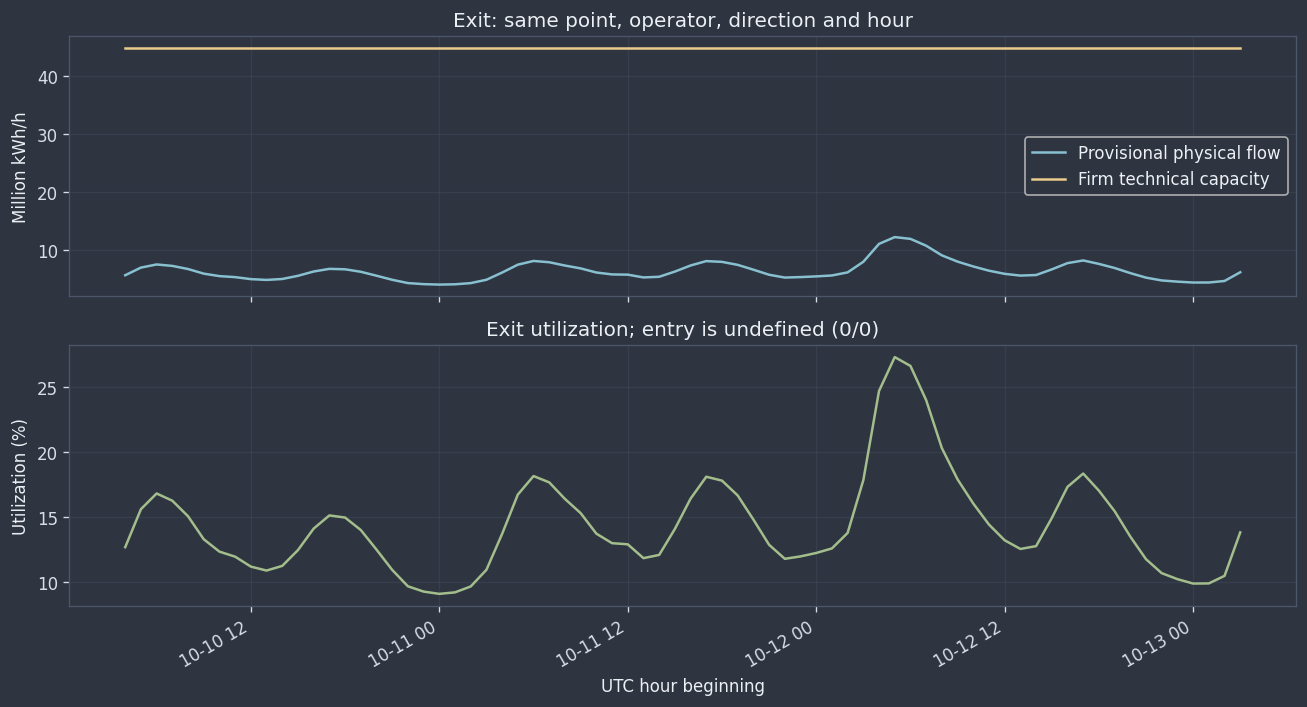

In [3]:
assert np.isnan(entry['ratio']).all()
assert np.isfinite(exit['ratio']).all()
print('Exit utilization min / mean / max (%):',np.round(100*np.array([exit['ratio'].min(),exit['ratio'].mean(),exit['ratio'].max()]),3).tolist())
print('Entry undefined hours:',int(np.isnan(entry['ratio']).sum()))
plt=setup_plot();fig,axes=plt.subplots(2,1,figsize=(11,6),sharex=True)
axes[0].plot(exit['times'],exit['flow']/1e6,color='#88C0D0',label='Provisional physical flow')
axes[0].plot(exit['times'],exit['values']['Firm Technical']/1e6,color='#EBCB8B',label='Firm technical capacity')
axes[0].set(ylabel='Million kWh/h',title='Exit: same point, operator, direction and hour');axes[0].legend()
axes[1].plot(exit['times'],100*exit['ratio'],color='#A3BE8C')
axes[1].set(ylabel='Utilization (%)',xlabel='UTC hour beginning',title='Exit utilization; entry is undefined (0/0)')
for ax in axes:ax.grid(alpha=.3)
fig.autofmt_xdate();fig.tight_layout();plt.show()

## 3. Fully booked does not mean fully used
Exit firm booked capacity equals technical capacity, while reported firm
available and interruptible quantities are zero. Technical − booked − available
reconciles here, but that is an observed sample identity, not a universal rule.
Physical flow averages about 14.39% of technical capacity despite full booking.
Capacity rights and actual transport measure different things. Zero available
capacity must not be used as the utilization denominator or read as an outage.

We keep entry and exit separate and do not sum different operators' reports.
This point's label and a single operator's records do not establish a network
aggregate. No attribution to individual shippers or causal explanation follows.

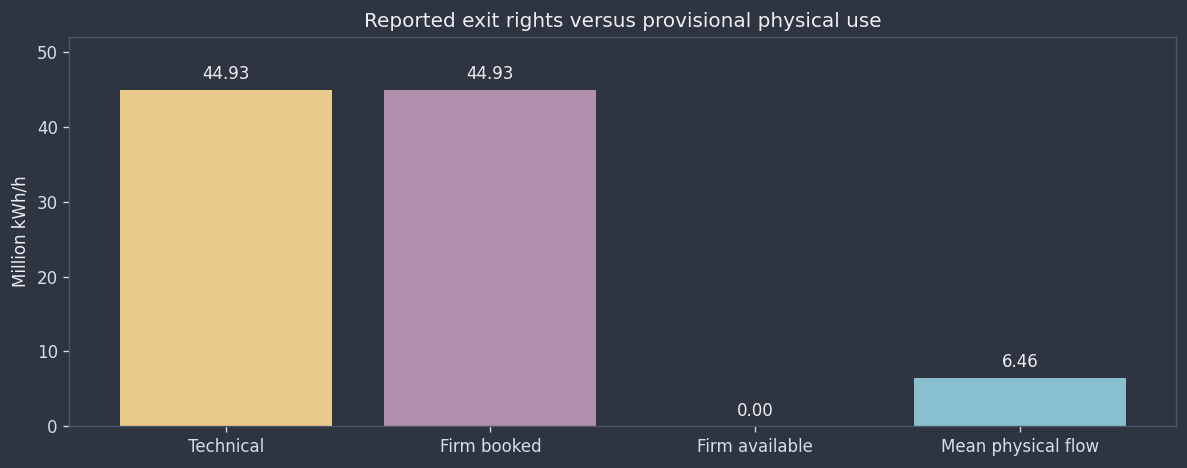

In [4]:
v=exit['values']
np.testing.assert_allclose(v['Firm Technical']-v['Firm Booked']-v['Firm Available'],0)
fig,ax=plt.subplots(figsize=(10,4))
labels=['Technical','Firm booked','Firm available','Mean physical flow']
values=[v['Firm Technical'].mean(),v['Firm Booked'].mean(),v['Firm Available'].mean(),exit['flow'].mean()]
bars=ax.bar(labels,np.array(values)/1e6,color=['#EBCB8B','#B48EAD','#D8DEE9','#88C0D0'])
ax.bar_label(bars,fmt='%.2f',padding=4,color='#ECEFF4');ax.set_ylim(0,52)
ax.set(ylabel='Million kWh/h',title='Reported exit rights versus provisional physical use');fig.tight_layout();plt.show()

## 4. Capacity known at a cutoff is not a forecast of flow
Four retained collector-as-of requests at 10 October 04:00 UTC return the same
interval histories as latest. Their receipts do not exceed that cutoff. The
subsequent flow outcomes are retrospective; this is not a predictive backtest.
Source-published as-of is unsupported. Withdrawals to NA and interval tombstones
are incompletely represented, so matching latest and as-of cannot prove perfect
reconstruction of the source's historical state.

The 72 hours have constant denominators; the mean hourly percentage equals
total flow energy divided by total technical-capacity energy. With changing
capacity, report the intended weighting rather than assuming those means agree.

In [5]:
assert all(a['collector_asof_equal'] for a in c['audit'].values())
energy_ratio=exit['flow'].sum()/v['Firm Technical'].sum()
np.testing.assert_allclose(energy_ratio,exit['ratio'].mean())
print('Three-day flow / capacity energy (%):',round(100*energy_ratio,3))

Three-day flow / capacity energy (%): 14.389


## Exercise and next evidence
Why does a zero result from the narrow capacity query not authorize filling
missing denominators with zero? The query excluded intervals that started
earlier. Why can 100% booked capacity coexist with 14% physical utilization?
Rights reserve capacity; realized transport need not use it all.
Broader conclusions require additional observed points, revised flow vintages,
and verified overlap/withdrawal semantics. This notebook supplies one bounded
case, with provisional outcomes and undefined entry ratios kept visible.
Source: retained EWB ENTSOG descriptors, complete query captures, and the
existing NB-11-ENTSOG flow receipt. No fresh API request runs inside the notebook.